We will start by importing the necessary libraries for exploring the data

In [236]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Load data and separate target to rest of dataset
raw = pd.read_csv('Telco-Customer-Churn.csv')
churn = raw['Churn']
data = raw.drop(['Churn', 'customerID'],axis=1)

# Success
print('Data loaded successfully.')

Data loaded successfully.


## Exploratory Data Analysis

### Exploring the dataset

In [237]:
data.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65


---

In [238]:
print(churn.value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


We notice that there is a moderate class imbalance in the data. This is significant as it allows us to consider evaluation metrics in a more stringent manner. A model that predicts 'No' only would achieve around 73/74% accuracy despite identifying no actual churners. We must consider our recall, precision, f1-score, and ROC-AUC metrics as more important metrics of evaluation.

- Recall: how many positives did the model predict against all the positives that exist -> higher means we got more real positive cases, but also can predict more false positives (avoids false negatives)
- Precision: a little more strict - models how many actual positives against all the predictions -> higher means we got more reliable predictions, lowering false positives but also can predict more false negatives (avoids false alarms)

---

For clarity, we will store the numerical and categorical columns in separate variables.

In [239]:
num_cols = data.select_dtypes(include=np.number).columns
cat_cols = data.select_dtypes(include='str').columns

print(num_cols)
print(cat_cols)

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges'], dtype='str')
Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod', 'TotalCharges'],
      dtype='str')


Looking at the categorical columns, we notice that TotalCharges is actually numeric, but it is listed as categorical. Upon exploration of the dataset, some columns are empty, filled with a space. We will change it to numeric.

In [240]:
data['TotalCharges'] = pd.to_numeric(raw['TotalCharges'], errors='coerce')
# Assign the numeric and categorical columns again
num_cols = data.select_dtypes(include=np.number).columns
cat_cols = data.select_dtypes(include='str').columns

print(num_cols)
print(cat_cols)

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='str')
Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='str')


In [241]:
missing = data.isna().sum()
missing_cols = missing[missing > 0].sort_values(ascending=False)
if len(missing_cols)>0:
    print(missing_cols)
else:
    print('No columns with missing values')

TotalCharges    11
dtype: int64


### Exploratory Feature Analysis: Contract vs. Churn

We will start by performing univariate feature analysis with Contract and its relationship to churn. We will start by creating a contingency table between the two. Using normalize, we will create a relative frequency table. By changing the parameter `normalize`, between index and column, we will get, respectively, the distribution of:
1. Whether customer churned given their contract type
2. Customers' contract type given whether they churned

In [ ]:
# Display relative frequency tables for conditional probabilities
print("Churn among contract types:\n{}".format(pd.crosstab(data['Contract'],churn,normalize='index').round(3)))
print("\nContract types among churn:\n{}".format(pd.crosstab(data['Contract'],churn,normalize='columns').round(3)))

Churn among contract types:
Churn              No    Yes
Contract                    
Month-to-month  0.573  0.427
One year        0.887  0.113
Two year        0.972  0.028

Contract types among churn:
Churn              No    Yes
Contract                    
Month-to-month  0.429  0.886
One year        0.253  0.089
Two year        0.318  0.026


We notice that churn is most likely in the month-to-month contract type, considerably so, with ~42.7% of those in that contract type churning. We also notice that the month-to-month contract makes up most of the churned customers, substantially. To understand why, further, we could look at the distribution of contract types among the dataset.

In [199]:
print(data['Contract'].value_counts(normalize=True))

Contract
Month-to-month    0.550192
Two year          0.240664
One year          0.209144
Name: proportion, dtype: float64


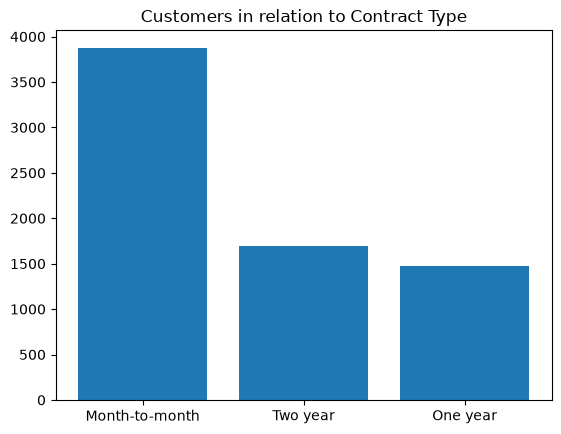

In [200]:
plt.bar(x=data['Contract'].value_counts().index, height=data['Contract'].value_counts())
plt.title(label='Customers in relation to Contract Type')
plt.show()

We notice that the month-to-month contract type dominates the dataset, about 55% of the contracts in it are monthly. While this subset is overrepresented, it suffices to say that it still has a considerable impact on churn, as we observed the ~0.427 probability of churn given a m2m contract. This does, however, affect the second tables findings, as the m2m contracts making up most of the churned base is due part in fact that it makes up most of the dataset.

Using: $$\text{H}_{o}\text{: contract and churn are independent,}\quad \text{H}_{a}\text{: contract and churn are dependent} $$

In [201]:
from scipy.stats import chi2_contingency

# Chi-test needs the contingency table, we do not normalize because it needs actual frequency counts
observed = pd.crosstab(data['Contract'],churn)
result=chi2_contingency(observed)
print('Successfully performed Chi-Squared Test.')


Successfully performed Chi-Squared Test.


In [202]:
# Print the results of the Chi-Squared Test
print(f"Test statistic: {result.statistic.round(3)}")
print(f"p-value: {result.pvalue}")
print(f"Degrees of freedom: {result.dof}")
print(f"Expected counts anticipated under Ho:\n{result.expected_freq.round(3)}")

Test statistic: 1184.597
p-value: 5.863038300673393e-258
Degrees of freedom: 2
Expected counts anticipated under Ho:
[[2846.692 1028.308]
 [1082.11   390.89 ]
 [1245.198  449.802]]


At the significance level of 5%, there is overwhelming evidence of an association between contract and churn. This concludes our exploration for Contract vs. Churn. We will move onto creating a more efficient method of exploring the other models efficiently, and measuring the predictive contributions through the building of a model.

---

Recalling some of the columns, we can make obvious connections between some. Particularly, we have:
- `PhoneService` and `MultipleLines`: Multiple lines is dependent on whether the customer even has a phone service. 
- `InternetService`,`OnlineSecurity`,`OnlineBackup`,`DeviceProtection`,`TechSupport`,`StreamingTV`,`StreamingMovies`: All the listed columns are dependent on whether the customer has internet service.

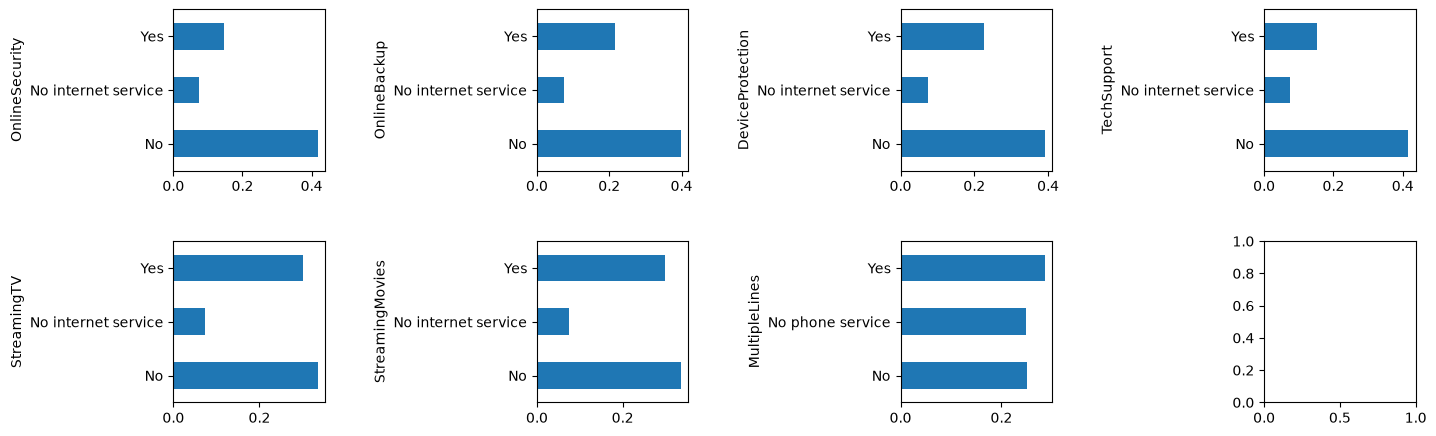

In [203]:
fig, axes = plt.subplots(2, 4, figsize=(15, 5))
children = ['OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies','MultipleLines']

# Make bar plots for each relative frequency table
for child,ax in zip(children,axes.flat):
    # Churn rates against their status (Yes, No, No internet service)
    rates=pd.crosstab(data[child],churn,normalize='index')
    rates['Yes'].plot(kind='barh', ax=ax)
    plt.tight_layout(pad=3)
plt.show()

Customers subscribed to Online Security and Tech Support exhibit substantially lower churn rates compared to customers with internet services who do subscribe. Streaming services show a weaker relationship with churn, both those who do subscribe and don't exhibit higher churn rates. Customers without internet services exhibit low churn as they represent the same underlying customer group. With phone service, we observe that customers subscribed to multiple lines actually exhibit a higher churn rate compared to those with a single line. "No" and "No phone service" represent the same customer group, hence their equal values.

Since we have no columns with missing values, we do not need to 'clean' our data before we proceed. We may move onto preprocessing and developing models.

---

## Preprocessing and Developing a Model

We will start by splitting our data into training and validation subsets to avoid data leakage. One important thing to recall is that we had a class imbalance. We will use `stratify` to ensure the training/validation subsets maintain the same proportion of class labels.

In [251]:
from sklearn.model_selection import train_test_split

X_train,X_val,y_train,y_val=train_test_split(data,churn,test_size=0.2,random_state=10,stratify=churn)

# Complete
print('Train-test split completed.')

Train-test split completed.


For the categorical and numerical transformers, we will impute using SimpleImputer with the constant strategy. We will scale the numeric values with respect to their column to prevent features w/ larger magnitudes from dominating the model's calculations.

In [274]:
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate,StratifiedKFold
from sklearn.metrics import make_scorer,precision_score, recall_score,f1_score

# Success
print("Imported all libraries successfully.")

Imported all libraries successfully.


In [275]:
categorical_transformer=Pipeline(steps=[
    ('imputer',SimpleImputer(strategy='constant')),
    ('onehot',OneHotEncoder(handle_unknown='ignore'))
    ])
numeric_transformer=Pipeline(steps=[
    ('imputer',SimpleImputer(strategy='constant')),
    ('scaler',StandardScaler())
])
preprocessor = ColumnTransformer(transformers=[
    ('num',numeric_transformer,num_cols),
    ('cat',categorical_transformer,cat_cols)
    ])

### The initial model: LogisticRegression

We will start by using a Logistic Regression model to establish a baseline for predicting customer churn. Logistic Regression is a suitable starting point for binary classification problems, as it estimates the probability of an observation belonging to a particular class.

Its relative simplicity, computational efficiency, and interpretability make it useful for establishing a benchmark against which more complex models, such as Random Forest and XGBoost, can be evaluated.


We will assess the model using 5-fold stratified cross-validation, measuring accuracy, precision, recall, F1-score, and ROC-AUC. Particular attention will be given to recall and F1-score, as identifying customers at risk of churning is a primary objective.
Following the initial evaluation, we will investigate how different preprocessing strategies and classification thresholds affect model performance.

In [276]:
# Create logistic regression model
model = LogisticRegression(max_iter=100)
clf = Pipeline(steps=[('preprocessor', preprocessor),('model',model)])

In [277]:
# Create folds
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=10)

# Create scorers for key metrics
metrics = {
    'accuracy':'accuracy',
    'precision':make_scorer(precision_score, pos_label='Yes'),
    'recall':make_scorer(recall_score, pos_label='Yes'),
    'f1':make_scorer(f1_score, pos_label='Yes'),
    'roc_auc':'roc_auc'
    }

scores=cross_validate(clf,X_train,y_train,cv=cv,scoring=metrics)
for metric in metrics:
    print(f'{metric}: {scores['test_'+metric].mean():.4f}')

accuracy: 0.8106
precision: 0.6712
recall: 0.5625
f1: 0.6118
roc_auc: 0.8471


Upon iterating through strategies, the best results for this initial model are given by the constant strategy (specifically, for the numeric transformer). This is given that threshold of p >= 0.5 yields 'Yes' for churn. We will test changing the threshold. Lowering the threshold makes it easier for a customer to be classified as a churner, increasing recall or keeping it constant, and may cause a decrease in precision. Conversely, increasing the threshold, should lower recall, and increase precision.

In [297]:
from sklearn.model_selection import cross_val_predict

probs = cross_val_predict(
    clf,
    X_train,
    y_train,
    cv=cv,
    method='predict_proba'
)[:, 1]

results = []

for threshold in np.arange(0.2, 0.81, 0.05):
    preds = np.where(probs >= threshold, 'Yes', 'No')
    results.append({
        'threshold': round(threshold, 2),
        'precision': precision_score(y_train, preds, pos_label='Yes'),
        'recall': recall_score(y_train, preds, pos_label='Yes'),
        'f1': f1_score(y_train, preds, pos_label='Yes')
    })

threshold_results = pd.DataFrame(results).set_index('threshold')
print(threshold_results)

           precision    recall        f1
threshold                               
0.20        0.467252  0.854181  0.604068
0.25        0.506413  0.818729  0.625767
0.30        0.539585  0.765886  0.633121
0.35        0.562566  0.709699  0.627625
0.40        0.590095  0.661538  0.623778
0.45        0.628240  0.616054  0.622087
0.50        0.670654  0.562542  0.611859
0.55        0.697256  0.492977  0.577586
0.60        0.722628  0.397324  0.512732
0.65        0.761578  0.296990  0.427334
0.70        0.785166  0.205351  0.325557
0.75        0.839506  0.090970  0.164152
0.80        0.880952  0.024749  0.048146


To better visualize the results, we will plot Precision, Recall, F1 Score against the classification threshold.

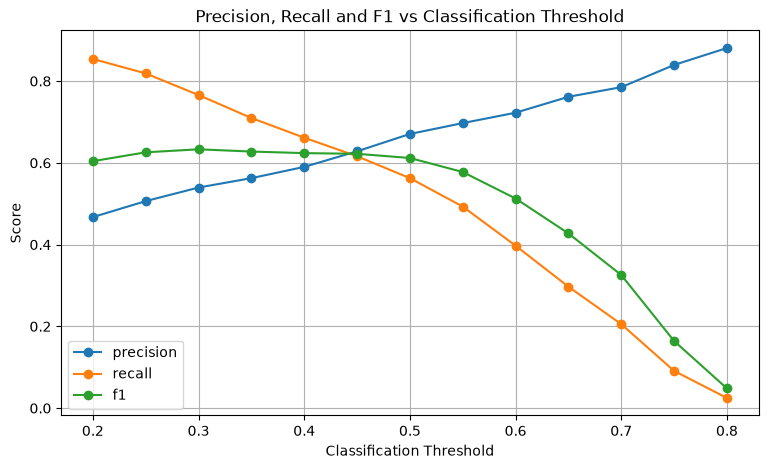

In [294]:
threshold_results.plot(
    y=['precision', 'recall', 'f1'],
    figsize=(9, 5),
    marker='o'
)

plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Precision, Recall and F1 vs Classification Threshold')
plt.grid(True)
plt.show()

The model demonstrates an expected precision-recall trade off as the classification threshold increases, indicating that the model becomes more selective when predicting model churn. F1-score reaches a maximum around 0.3, suggesting lower threshold provides a more favourable balance between recall and precision under the F1 metric. While ~0.45 produces nearly equal precision and recall, F1-score isn't maximized, therefore 0.30 is a promising candidate for further evaluation. To further note, F1-score is relatively stable between 0.25 and 0.45, suggesting some flexibility in selecting a threshold based on business requirements.

Whether the company wants to prioritize true positives, or minimize false negatives, they can do so without considerable sacrifice in the F1-score. We will move on to testing another model.

---